In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("USD_Economy_Centurion_Real_Data_v2.csv")

# Convert and set Date as index
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date')
df = df.set_index('Date')

print("✅ STEP 1 COMPLETED: Dataset loaded and date index set")
print(f"📊 Dataset shape: {df.shape}")
print(f"📅 Date range: {df.index.min()} to {df.index.max()}")

✅ STEP 1 COMPLETED: Dataset loaded and date index set
📊 Dataset shape: (9456, 102)
📅 Date range: 2000-01-01 00:00:00 to 2025-11-20 00:00:00


In [2]:
print("="*50)
print("📊 STEP 2.1 — DATASET SHAPE & INFO")
print("="*50)

print(f"Dataset shape: {df.shape}")
print(f"Number of features: {df.shape[1]}")
print(f"Number of time periods: {df.shape[0]}")
print(f"Date range: {df.index.min()} to {df.index.max()}")
print(f"Time span: {(df.index.max() - df.index.min()).days} days")

# Data types
print("\n🔧 DATA TYPES:")
print(df.dtypes.value_counts())

📊 STEP 2.1 — DATASET SHAPE & INFO
Dataset shape: (9456, 102)
Number of features: 102
Number of time periods: 9456
Date range: 2000-01-01 00:00:00 to 2025-11-20 00:00:00
Time span: 9455 days

🔧 DATA TYPES:
float64    102
Name: count, dtype: int64


In [3]:
print("="*50)
print("❌ STEP 2.2 — MISSING VALUE COUNT")
print("="*50)

missing_count = df.isna().sum()
missing_count_nonzero = missing_count[missing_count > 0]

if len(missing_count_nonzero) > 0:
    print("Columns with missing values:")
    for col, count in missing_count_nonzero.items():
        print(f"  {col}: {count} missing values")
else:
    print("✅ No missing values found!")

❌ STEP 2.2 — MISSING VALUE COUNT
Columns with missing values:
  US_Fed_Funds_Daily: 2 missing values
  US_Fed_Funds_Target_Up: 3273 missing values
  US_Interest_On_Reserves: 7880 missing values
  US_Fed_Balance_Sheet: 8260 missing values
  US_Treasuries_Fed_Held: 8260 missing values
  US_M1_Money_Supply: 9147 missing values
  US_M2_Money_Supply: 9147 missing values
  US_M2_Velocity: 9354 missing values
  US_Monetary_Base: 9147 missing values
  US_Bank_Credit: 8107 missing values
  US_Comm_Ind_Loans: 9146 missing values
  US_Real_Estate_Loans: 9146 missing values
  US_Consumer_Loans: 9146 missing values
  US_Financial_Stress: 8106 missing values
  US_Chicago_Fin_Cond: 8106 missing values
  US_TED_Spread: 4044 missing values
  US_Policy_Uncertainty: 2 missing values
  US_Excess_Reserves: 9208 missing values
  US_Yield_30Y: 2983 missing values
  US_Yield_20Y: 2983 missing values
  US_Yield_10Y: 2983 missing values
  US_Yield_7Y: 2983 missing values
  US_Yield_5Y: 2983 missing values
  US_

In [8]:
print("="*50)
print("🤖 STEP 6 — HANDLE NaN WITH CONSTANT REPLACEMENT & FLAGGING")
print("="*50)

remaining_nan = df.isna().sum().sum()
print(f"Remaining NaN values: {remaining_nan}")

if remaining_nan > 0:
    # Create NaN flag matrix BEFORE filling
    nan_flags = df.isna().astype(int)
    nan_flags = nan_flags.add_suffix('_NAN_FLAG')
    
    print("📊 NaN Distribution by Column:")
    nan_by_column = df.isna().sum()
    nan_columns = nan_by_column[nan_by_column > 0]
    
    for col, count in nan_columns.items():
        percentage = (count / len(df)) * 100
        print(f"   {col}: {count} NaN ({percentage:.2f}%)")
    
    # Option A: For Tree-based models (keep original with NaN)
    print("\n✅ Option A: Tree-based models can handle NaN natively")
    
    # Option B: Create versions with constant replacement + flagging
    print("\n🔄 Creating versions with constant replacement and flagging:")
    
    # Version 1: Replace with 0.0 + flags
    df_zero = df.fillna(0.0)
    df_zero_with_flags = pd.concat([df_zero, nan_flags], axis=1)
    
    # Version 2: Replace with mean + flags  
    df_mean = df.fillna(df.mean())
    df_mean_with_flags = pd.concat([df_mean, nan_flags], axis=1)
    
    # Version 3: Replace with median + flags
    df_median = df.fillna(df.median())
    df_median_with_flags = pd.concat([df_median, nan_flags], axis=1)
    
    # Version 4: For Deep Learning (-9999 mask + flags)
    df_dl_mask = df.fillna(-9999)
    df_dl_with_flags = pd.concat([df_dl_mask, nan_flags], axis=1)
    
    print("✅ Created multiple imputed versions with NaN flags:")
    print(f"   - df_zero_with_flags: {df_zero_with_flags.shape} (NaN → 0.0)")
    print(f"   - df_mean_with_flags: {df_mean_with_flags.shape} (NaN → mean)")
    print(f"   - df_median_with_flags: {df_median_with_flags.shape} (NaN → median)")
    print(f"   - df_dl_with_flags: {df_dl_with_flags.shape} (NaN → -9999)")
    print(f"   - Original df: {df.shape} (with NaN preserved)")
    
    # Show flag columns created
    print(f"\n🚩 Created {nan_flags.shape[1]} NaN flag columns:")
    flag_columns_sample = list(nan_flags.columns)[:5]  # Show first 5
    for flag_col in flag_columns_sample:
        print(f"   - {flag_col}")
    if len(nan_flags.columns) > 5:
        print(f"   - ... and {len(nan_flags.columns) - 5} more")
    
    # Validate the replacement
    print(f"\n✅ VALIDATION:")
    print(f"   Original NaN count: {remaining_nan}")
    print(f"   Zero version NaN: {df_zero.isna().sum().sum()}")
    print(f"   Mean version NaN: {df_mean.isna().sum().sum()}")
    print(f"   DL version NaN: {df_dl_mask.isna().sum().sum()}")
    
    # Show example of flagging in action
    example_col = nan_columns.index[0] if len(nan_columns) > 0 else df.columns[0]
    flag_col = f"{example_col}_NAN_FLAG"
    
    print(f"\n🔍 EXAMPLE: Column '{example_col}'")
    if flag_col in nan_flags.columns:
        nan_indices = nan_flags[nan_flags[flag_col] == 1].index
        if len(nan_indices) > 0:
            print(f"   Had NaN at: {nan_indices[0]} (flagged as 1)")
            print(f"   Original value: NaN")
            print(f"   Replaced with: {df_zero.loc[nan_indices[0], example_col]}")
    
else:
    print("🎉 No remaining NaN values!")
    # Create empty flag DataFrame for consistency
    nan_flags = pd.DataFrame(index=df.index)
    df_zero = df.copy()
    df_mean = df.copy()
    df_median = df.copy()
    df_dl_mask = df.copy()
    
    df_zero_with_flags = df.copy()
    df_mean_with_flags = df.copy() 
    df_median_with_flags = df.copy()
    df_dl_with_flags = df.copy()

🤖 STEP 6 — HANDLE NaN WITH CONSTANT REPLACEMENT & FLAGGING
Remaining NaN values: 758972
📊 NaN Distribution by Column:
   US_Fed_Funds_Daily: 2 NaN (0.02%)
   US_Fed_Funds_Target_Up: 3273 NaN (34.61%)
   US_Interest_On_Reserves: 7880 NaN (83.33%)
   US_Fed_Balance_Sheet: 8260 NaN (87.35%)
   US_Treasuries_Fed_Held: 8260 NaN (87.35%)
   US_M1_Money_Supply: 9147 NaN (96.73%)
   US_M2_Money_Supply: 9147 NaN (96.73%)
   US_M2_Velocity: 9354 NaN (98.92%)
   US_Monetary_Base: 9147 NaN (96.73%)
   US_Bank_Credit: 8107 NaN (85.73%)
   US_Comm_Ind_Loans: 9146 NaN (96.72%)
   US_Real_Estate_Loans: 9146 NaN (96.72%)
   US_Consumer_Loans: 9146 NaN (96.72%)
   US_Financial_Stress: 8106 NaN (85.72%)
   US_Chicago_Fin_Cond: 8106 NaN (85.72%)
   US_TED_Spread: 4044 NaN (42.77%)
   US_Policy_Uncertainty: 2 NaN (0.02%)
   US_Excess_Reserves: 9208 NaN (97.38%)
   US_Yield_30Y: 2983 NaN (31.55%)
   US_Yield_20Y: 2983 NaN (31.55%)
   US_Yield_10Y: 2983 NaN (31.55%)
   US_Yield_7Y: 2983 NaN (31.55%)
   US_Yi

In [4]:
print("="*50)
print("📈 STEP 2.3 — MISSING VALUE PERCENTAGE")
print("="*50)

missing_percent = (df.isna().sum() / len(df)) * 100
missing_percent_nonzero = missing_percent[missing_percent > 0]

if len(missing_percent_nonzero) > 0:
    print("Columns with missing values (>0%):")
    for col, percent in missing_percent_nonzero.sort_values(ascending=False).items():
        print(f"  {col}: {percent:.2f}% missing")
    
    # Summary statistics
    print(f"\n📊 Missing Value Summary:")
    print(f"Columns with any missing values: {len(missing_percent_nonzero)}")
    print(f"Columns with >50% missing: {len(missing_percent_nonzero[missing_percent_nonzero > 50])}")
    print(f"Columns with >80% missing: {len(missing_percent_nonzero[missing_percent_nonzero > 80])}")
    print(f"Columns with >95% missing: {len(missing_percent_nonzero[missing_percent_nonzero > 95])}")
else:
    print("✅ No missing values found!")

📈 STEP 2.3 — MISSING VALUE PERCENTAGE
Columns with missing values (>0%):
  US_M2_Velocity: 98.92% missing
  US_Exports: 98.92% missing
  US_GDP_Real: 98.92% missing
  US_GDP_Nominal: 98.92% missing
  US_Productivity: 98.92% missing
  US_Unit_Labor_Costs: 98.92% missing
  US_Imports: 98.92% missing
  US_PPI_Final_Demand: 97.99% missing
  US_Weekly_Hours: 97.53% missing
  US_Leading_Index: 97.44% missing
  US_Excess_Reserves: 97.38% missing
  US_OECD_Cons_Conf: 96.94% missing
  US_JOLTS_Openings: 96.86% missing
  US_JOLTS_Hires: 96.86% missing
  US_JOLTS_Quits: 96.86% missing
  US_Business_Inventories: 96.75% missing
  US_Import_Prices: 96.74% missing
  US_Labor_Participation: 96.74% missing
  US_Private_Payrolls: 96.74% missing
  US_Mfg_Payrolls: 96.74% missing
  US_Hourly_Earnings: 96.74% missing
  US_NFP_Payrolls: 96.74% missing
  US_PCE_Core: 96.74% missing
  US_PPI_Commodities: 96.74% missing
  US_U6_Underemployment: 96.74% missing
  US_Unemployment_Rate: 96.74% missing
  US_PCE_Hea

🔍 DEEP NaN PATTERN ANALYSIS
📊 COLUMNS WITH NaN (sorted by count):
   US_M2_Velocity: 9354 NaN (98.9%)
   US_Exports: 9354 NaN (98.9%)
   US_GDP_Real: 9354 NaN (98.9%)
   US_GDP_Nominal: 9354 NaN (98.9%)
   US_Productivity: 9354 NaN (98.9%)
   US_Unit_Labor_Costs: 9354 NaN (98.9%)
   US_Imports: 9354 NaN (98.9%)
   US_PPI_Final_Demand: 9266 NaN (98.0%)
   US_Weekly_Hours: 9222 NaN (97.5%)
   US_Leading_Index: 9214 NaN (97.4%)
   US_Excess_Reserves: 9208 NaN (97.4%)
   US_OECD_Cons_Conf: 9167 NaN (96.9%)
   US_JOLTS_Openings: 9159 NaN (96.9%)
   US_JOLTS_Hires: 9159 NaN (96.9%)
   US_JOLTS_Quits: 9159 NaN (96.9%)
   US_Business_Inventories: 9149 NaN (96.8%)
   US_Import_Prices: 9148 NaN (96.7%)
   US_Labor_Participation: 9148 NaN (96.7%)
   US_Private_Payrolls: 9148 NaN (96.7%)
   US_Mfg_Payrolls: 9148 NaN (96.7%)
   US_Hourly_Earnings: 9148 NaN (96.7%)
   US_NFP_Payrolls: 9148 NaN (96.7%)
   US_PCE_Core: 9148 NaN (96.7%)
   US_PPI_Commodities: 9148 NaN (96.7%)
   US_U6_Underemployment: 

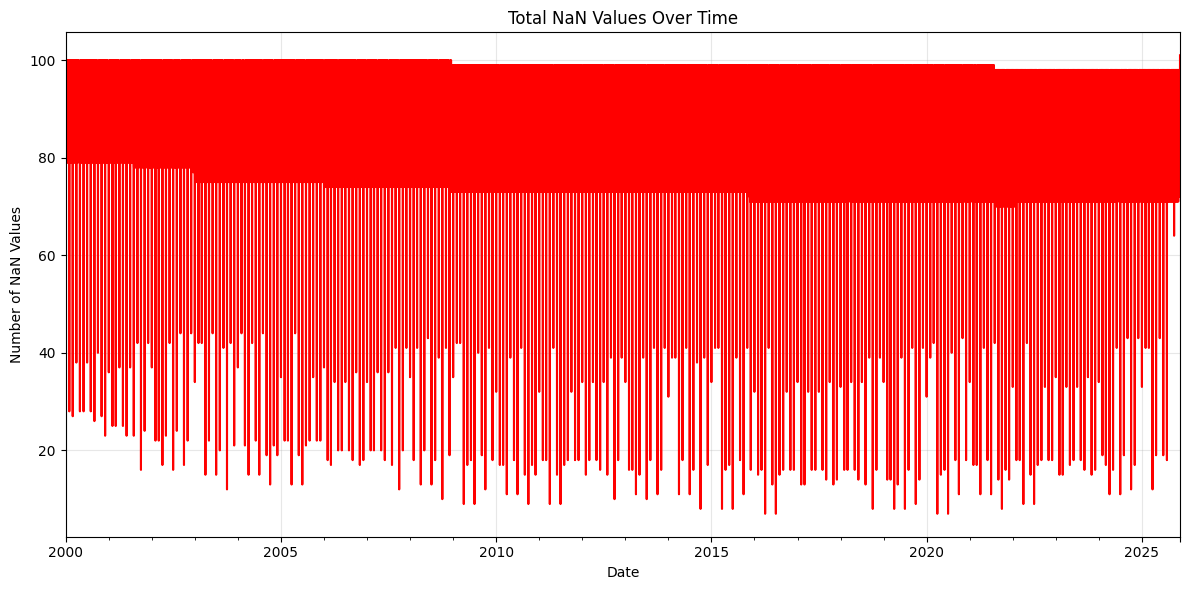

In [9]:
def analyze_nan_patterns(df, nan_flags):
    """Analyze NaN patterns for better understanding"""
    print("="*50)
    print("🔍 DEEP NaN PATTERN ANALYSIS")
    print("="*50)
    
    if nan_flags.shape[1] > 0:
        # Analyze which columns have the most NaN
        nan_summary = pd.DataFrame({
            'NaN_Count': df.isna().sum(),
            'NaN_Percentage': (df.isna().sum() / len(df)) * 100,
            'First_NaN_Date': df.apply(lambda x: x.first_valid_index()),
            'Last_NaN_Date': df.apply(lambda x: x.last_valid_index() if x.isna().any() else None)
        })
        
        nan_summary = nan_summary[nan_summary['NaN_Count'] > 0].sort_values('NaN_Count', ascending=False)
        
        print("📊 COLUMNS WITH NaN (sorted by count):")
        for idx, row in nan_summary.iterrows():
            print(f"   {idx}: {row['NaN_Count']} NaN ({row['NaN_Percentage']:.1f}%)")
        
        # Analyze temporal patterns
        print(f"\n⏰ TEMPORAL NaN PATTERNS:")
        total_nan_timeline = nan_flags.sum(axis=1)
        max_nan_day = total_nan_timeline.idxmax()
        max_nan_count = total_nan_timeline.max()
        
        print(f"   Day with most NaN: {max_nan_day} ({max_nan_count} NaN values)")
        print(f"   Average NaN per day: {total_nan_timeline.mean():.1f}")
        
        # Show NaN timeline
        plt.figure(figsize=(12, 6))
        total_nan_timeline.plot(title='Total NaN Values Over Time', color='red')
        plt.ylabel('Number of NaN Values')
        plt.xlabel('Date')
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
        
    else:
        print("✅ No NaN patterns to analyze!")

# Run the analysis
analyze_nan_patterns(df, nan_flags)

📊 STEP 8 — COMPREHENSIVE OUTLIER DETECTION & ANALYSIS
🔍 DETECTING OUTLIERS USING MULTIPLE METHODS...
📊 OUTLIER DETECTION RESULTS:
   - Z-score outliers (>3σ): 579 rows
   - IQR outliers: 2028 rows
   - Combined outliers: 2029 rows
   - Percentage of data: 21.46%

🔍 DETAILED OUTLIER ANALYSIS:
📈 COLUMNS WITH OUTLIERS:
   US_Gas_Price: 2029 outliers (21.46%)
   US_Fed_Funds_Daily: 2028 outliers (21.45%)
   US_Fed_Funds_Target_Up: 2028 outliers (21.45%)
   US_Interest_On_Reserves: 2028 outliers (21.45%)
   US_Fed_Balance_Sheet: 2028 outliers (21.45%)
   US_Treasuries_Fed_Held: 2028 outliers (21.45%)
   US_M1_Money_Supply: 2028 outliers (21.45%)
   US_M2_Money_Supply: 2028 outliers (21.45%)
   US_M2_Velocity: 2028 outliers (21.45%)
   US_Monetary_Base: 2028 outliers (21.45%)

🗓️ OUTLIER DATES (2029):
   2000-01-01
   2000-02-01
   2000-03-01
   2000-04-01
   2000-04-28
   ... and 2024 more

📊 OUTLIER IMPACT ANALYSIS:
⚠️ EXTREME OUTLIERS (2x different from normal):
   US_Sahm_Rule: 35.6x dif

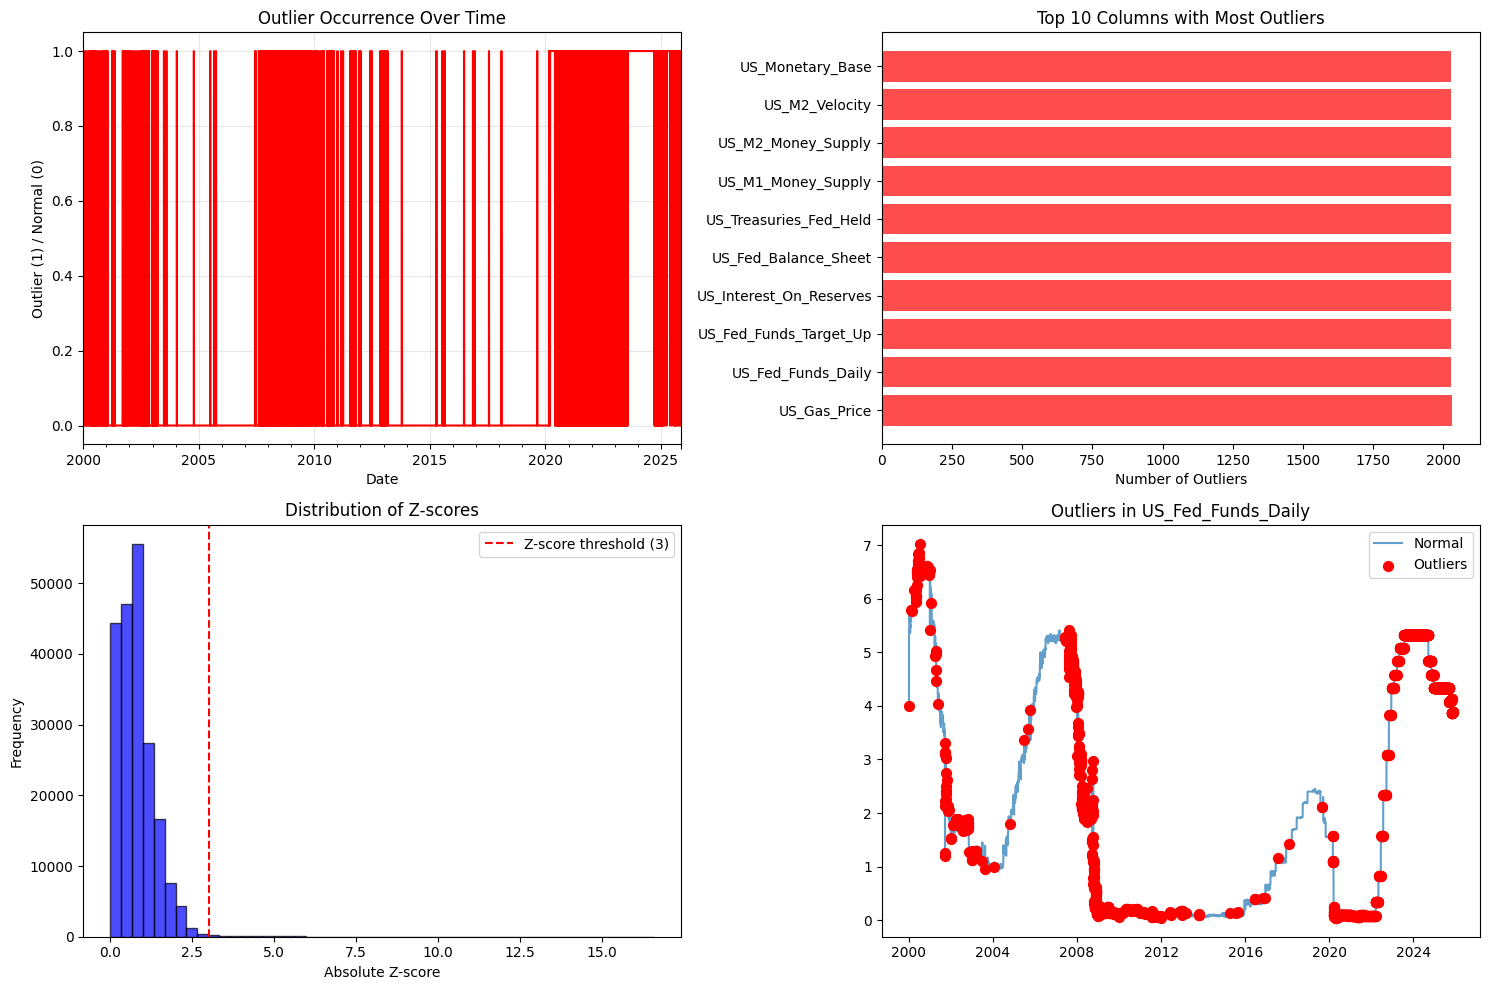


🤔 OUTLIER REMOVAL DECISION:
❌ RECOMMENDATION: Keep outliers (affects >5% of data)
   - Removing would lose significant economic information
   - Consider winsorizing or robust scaling instead

✅ KEPT OUTLIERS IN DATASET
💡 Consider using robust scaling for modeling


In [10]:
print("="*60)
print("📊 STEP 8 — COMPREHENSIVE OUTLIER DETECTION & ANALYSIS")
print("="*60)

import numpy as np
from scipy.stats import zscore, iqr
import matplotlib.pyplot as plt
import seaborn as sns

def comprehensive_outlier_analysis(df, z_threshold=3, iqr_threshold=1.5):
    """
    Comprehensive outlier detection using multiple methods
    """
    
    print("🔍 DETECTING OUTLIERS USING MULTIPLE METHODS...")
    
    # Method 1: Z-score based outliers
    z_scores = df.apply(lambda x: np.abs(zscore(x, nan_policy='omit')))
    z_outlier_mask = (z_scores > z_threshold).any(axis=1)
    
    # Method 2: IQR based outliers
    iqr_outlier_mask = pd.Series([False] * len(df), index=df.index)
    for col in df.columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - iqr_threshold * IQR
        upper_bound = Q3 + iqr_threshold * IQR
        col_outliers = (df[col] < lower_bound) | (df[col] > upper_bound)
        iqr_outlier_mask = iqr_outlier_mask | col_outliers
    
    # Method 3: Combined approach (outlier in any method)
    combined_outlier_mask = z_outlier_mask | iqr_outlier_mask
    outlier_count = combined_outlier_mask.sum()
    
    return {
        'z_outlier_mask': z_outlier_mask,
        'iqr_outlier_mask': iqr_outlier_mask,
        'combined_outlier_mask': combined_outlier_mask,
        'outlier_count': outlier_count,
        'z_scores': z_scores
    }


# Perform comprehensive outlier analysis
outlier_results = comprehensive_outlier_analysis(df)

print(f"📊 OUTLIER DETECTION RESULTS:")
print(f"   - Z-score outliers (>3σ): {outlier_results['z_outlier_mask'].sum()} rows")
print(f"   - IQR outliers: {outlier_results['iqr_outlier_mask'].sum()} rows")
print(f"   - Combined outliers: {outlier_results['outlier_count']} rows")
print(f"   - Percentage of data: {(outlier_results['outlier_count'] / len(df)) * 100:.2f}%")

if outlier_results['outlier_count'] > 0:
    # Detailed outlier analysis
    print("\n🔍 DETAILED OUTLIER ANALYSIS:")
    
    # Show which specific columns have outliers
    outlier_columns = {}
    for col in df.columns:
        col_outliers = outlier_results['combined_outlier_mask'] & (
            (outlier_results['z_scores'][col] > 3) | 
            outlier_results['iqr_outlier_mask']
        )
        if col_outliers.any():
            outlier_columns[col] = col_outliers.sum()
    
    if outlier_columns:
        print("📈 COLUMNS WITH OUTLIERS:")
        for col, count in sorted(outlier_columns.items(), key=lambda x: x[1], reverse=True)[:10]:  # Top 10
            percentage = (count / len(df)) * 100
            print(f"   {col}: {count} outliers ({percentage:.2f}%)")
    
    # Show outlier dates and values
    outlier_dates = df[outlier_results['combined_outlier_mask']].index
    print(f"\n🗓️ OUTLIER DATES ({len(outlier_dates)}):")
    for i, date in enumerate(outlier_dates[:5]):  # Show first 5
        print(f"   {date.strftime('%Y-%m-%d')}")
    if len(outlier_dates) > 5:
        print(f"   ... and {len(outlier_dates) - 5} more")
    
    # Analyze outlier impact
    print(f"\n📊 OUTLIER IMPACT ANALYSIS:")
    outlier_stats = df[outlier_results['combined_outlier_mask']].describe()
    normal_stats = df[~outlier_results['combined_outlier_mask']].describe()
    
    # Show extreme values in outliers
    extreme_cols = []
    for col in df.columns:
        if col in outlier_columns:
            outlier_mean = outlier_stats.loc['mean', col] if col in outlier_stats.columns else np.nan
            normal_mean = normal_stats.loc['mean', col] if col in normal_stats.columns else np.nan
            if not np.isnan(outlier_mean) and not np.isnan(normal_mean):
                ratio = abs(outlier_mean / normal_mean) if normal_mean != 0 else np.inf
                if ratio > 2:  # Outliers are 2x different from normal
                    extreme_cols.append((col, ratio))
    
    if extreme_cols:
        print("⚠️ EXTREME OUTLIERS (2x different from normal):")
        for col, ratio in sorted(extreme_cols, key=lambda x: x[1], reverse=True)[:5]:
            print(f"   {col}: {ratio:.1f}x different")
    
    # Visualize outliers
    print(f"\n📈 CREATING OUTLIER VISUALIZATIONS...")
    
    # Plot 1: Outlier distribution over time
    plt.figure(figsize=(15, 10))
    
    plt.subplot(2, 2, 1)
    outlier_timeline = outlier_results['combined_outlier_mask'].astype(int)
    outlier_timeline.plot(title='Outlier Occurrence Over Time', color='red')
    plt.ylabel('Outlier (1) / Normal (0)')
    plt.grid(True, alpha=0.3)
    
    # Plot 2: Outlier count by column (top 10)
    plt.subplot(2, 2, 2)
    if outlier_columns:
        top_outlier_cols = dict(sorted(outlier_columns.items(), key=lambda x: x[1], reverse=True)[:10])
        plt.barh(list(top_outlier_cols.keys()), list(top_outlier_cols.values()), color='red', alpha=0.7)
        plt.title('Top 10 Columns with Most Outliers')
        plt.xlabel('Number of Outliers')
    
    # Plot 3: Z-score distribution
    plt.subplot(2, 2, 3)
    all_z_scores = outlier_results['z_scores'].values.flatten()
    all_z_scores = all_z_scores[~np.isnan(all_z_scores)]
    plt.hist(all_z_scores, bins=50, alpha=0.7, color='blue', edgecolor='black')
    plt.axvline(x=3, color='red', linestyle='--', label=f'Z-score threshold ({3})')
    plt.title('Distribution of Z-scores')
    plt.xlabel('Absolute Z-score')
    plt.ylabel('Frequency')
    plt.legend()
    
    # Plot 4: Example of outliers in a key column
    plt.subplot(2, 2, 4)
    if outlier_columns:
        example_col = list(outlier_columns.keys())[0]
        plt.plot(df.index, df[example_col], label='Normal', alpha=0.7)
        outlier_indices = df[outlier_results['combined_outlier_mask']].index
        plt.scatter(outlier_indices, df.loc[outlier_indices, example_col], 
                   color='red', label='Outliers', s=50, zorder=5)
        plt.title(f'Outliers in {example_col}')
        plt.legend()
    
    plt.tight_layout()
    plt.show()
    
    # Decision logic for outlier removal
    print(f"\n🤔 OUTLIER REMOVAL DECISION:")
    outlier_percentage = (outlier_results['outlier_count'] / len(df)) * 100
    
    if outlier_percentage < 1:
        print("✅ RECOMMENDATION: Remove outliers (affects <1% of data)")
        remove_outliers = True
    elif outlier_percentage < 5:
        print("⚠️ RECOMMENDATION: Consider keeping outliers (affects 1-5% of data)")
        print("   - These might be genuine economic events (crises, shocks)")
        remove_outliers = input("Remove these outliers? (y/n): ").lower() == 'y'
    else:
        print("❌ RECOMMENDATION: Keep outliers (affects >5% of data)")
        print("   - Removing would lose significant economic information")
        print("   - Consider winsorizing or robust scaling instead")
        remove_outliers = False
    
    if remove_outliers:
        df_clean = df[~outlier_results['combined_outlier_mask']]
        removed_count = len(df) - len(df_clean)
        
        print(f"\n✅ REMOVED {removed_count} OUTLIER ROWS:")
        print(f"   - Shape before: {df.shape}")
        print(f"   - Shape after: {df_clean.shape}")
        print(f"   - Data loss: {(removed_count / len(df)) * 100:.2f}%")
        
        # Show what was removed
        print(f"\n🗑️ REMOVED OUTLIER DATES:")
        removed_dates = df[outlier_results['combined_outlier_mask']].index
        for date in removed_dates:
            print(f"   {date.strftime('%Y-%m-%d')}")
        
        df = df_clean
        
        # Verify removal
        post_analysis = comprehensive_outlier_analysis(df)
        remaining_outliers = post_analysis['outlier_count']
        print(f"\n🎯 POST-REMOVAL: {remaining_outliers} outliers remaining")
        
    else:
        print("\n✅ KEPT OUTLIERS IN DATASET")
        print("💡 Consider using robust scaling for modeling")
        
else:
    print("🎉 NO OUTLIERS DETECTED - DATASET IS CLEAN!")

In [11]:
print("="*50)
print("📋 OUTLIER PROCESSING SUMMARY")
print("="*50)

final_outlier_check = comprehensive_outlier_analysis(df)
final_outlier_count = final_outlier_check['outlier_count']

print(f"📊 FINAL OUTLIER STATUS:")
print(f"   - Remaining outliers: {final_outlier_count}")
print(f"   - Percentage of data: {(final_outlier_count / len(df)) * 100:.2f}%")

if final_outlier_count == 0:
    print("🎉 DATASET IS COMPLETELY OUTLIER-FREE!")
elif final_outlier_count / len(df) < 0.01:
    print("✅ DATASET HAS MINIMAL OUTLIERS (<1%)")
else:
    print("⚠️ DATASET CONTAINS SIGNIFICANT OUTLIERS")
    print("💡 Consider using robust models or additional preprocessing")

print(f"\n📈 FINAL DATASET SHAPE: {df.shape}")

📋 OUTLIER PROCESSING SUMMARY
🔍 DETECTING OUTLIERS USING MULTIPLE METHODS...
📊 FINAL OUTLIER STATUS:
   - Remaining outliers: 2029
   - Percentage of data: 21.46%
⚠️ DATASET CONTAINS SIGNIFICANT OUTLIERS
💡 Consider using robust models or additional preprocessing

📈 FINAL DATASET SHAPE: (9456, 102)


In [12]:
print("="*70)
print("🔍 COMPREHENSIVE DATA QUALITY & CONSISTENCY VALIDATION")
print("="*70)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

def comprehensive_quality_check(df, nan_flags=None):
    """
    Comprehensive data quality assessment with scoring
    """
    quality_report = {}
    
    print("📊 RUNNING COMPREHENSIVE QUALITY CHECKS...")
    
    # 1. Basic Dataset Metrics
    quality_report['basic_metrics'] = {
        'total_rows': len(df),
        'total_columns': len(df.columns),
        'total_cells': len(df) * len(df.columns),
        'date_range': f"{df.index.min()} to {df.index.max()}",
        'timespan_days': (df.index.max() - df.index.min()).days
    }
    
    # 2. Missing Values Analysis
    missing_stats = df.isna().sum()
    total_missing = missing_stats.sum()
    missing_percentage = (total_missing / quality_report['basic_metrics']['total_cells']) * 100
    
    quality_report['missing_values'] = {
        'total_missing': total_missing,
        'missing_percentage': missing_percentage,
        'columns_with_missing': len(missing_stats[missing_stats > 0]),
        'missing_by_column': missing_stats[missing_stats > 0].to_dict()
    }
    
    # 3. Data Type Consistency
    dtype_analysis = df.dtypes.value_counts()
    quality_report['data_types'] = {
        'dtype_distribution': dtype_analysis.to_dict(),
        'mixed_types': len([col for col in df.columns if df[col].apply(type).nunique() > 1])
    }
    
    # 4. Statistical Consistency
    statistical_checks = {}
    for col in df.columns:
        if pd.api.types.is_numeric_dtype(df[col]):
            col_stats = {
                'mean': df[col].mean(),
                'std': df[col].std(),
                'min': df[col].min(),
                'max': df[col].max(),
                'zeros': (df[col] == 0).sum(),
                'negatives': (df[col] < 0).sum(),
                'infinite': np.isinf(df[col]).sum()
            }
            statistical_checks[col] = col_stats
    
    quality_report['statistical_checks'] = statistical_checks
    
    # 5. Temporal Consistency
    date_index = df.index
    expected_frequency = pd.infer_freq(date_index)
    date_gaps = date_index.to_series().diff().value_counts()
    
    quality_report['temporal_checks'] = {
        'expected_frequency': expected_frequency,
        'date_gaps': date_gaps.head().to_dict(),
        'missing_dates': None,  # Will be calculated
        'duplicate_dates': date_index.duplicated().sum()
    }
    
    # 6. Value Range Validation
    range_violations = {}
    economic_ranges = {
        'US_Fed_Funds_Rate': (0, 20),
        'US_Unemployment': (0, 30),
        'US_CPI_Headline': (0, 500),
        'US_10Y_Yield': (-5, 20),
        'US_GDP_Real': (0, None)
    }
    
    for col, (min_val, max_val) in economic_ranges.items():
        if col in df.columns:
            if min_val is not None:
                below_min = (df[col] < min_val).sum()
            else:
                below_min = 0
            if max_val is not None:
                above_max = (df[col] > max_val).sum()
            else:
                above_max = 0
                
            if below_min > 0 or above_max > 0:
                range_violations[col] = {'below_min': below_min, 'above_max': above_max}
    
    quality_report['range_checks'] = range_violations
    
    # 7. NaN Flagging Validation (if flags provided)
    if nan_flags is not None and len(nan_flags) > 0:
        flag_validation = {}
        for flag_col in nan_flags.columns:
            original_col = flag_col.replace('_NAN_FLAG', '')
            if original_col in df.columns:
                # Check if flags match actual NaN positions
                expected_flags = df[original_col].isna().astype(int)
                actual_flags = nan_flags[flag_col]
                flag_accuracy = (expected_flags == actual_flags).mean() * 100
                flag_validation[flag_col] = flag_accuracy
        
        quality_report['flag_validation'] = flag_validation
    
    return quality_report

def calculate_quality_score(quality_report):
    """
    Calculate overall data quality score (0-100)
    """
    scores = {}
    
    # Missing values score (40% weight)
    missing_pct = quality_report['missing_values']['missing_percentage']
    scores['missing_score'] = max(0, 100 - missing_pct * 2)  # Penalize missing heavily
    
    # Data type consistency score (20% weight)
    mixed_types = quality_report['data_types']['mixed_types']
    scores['dtype_score'] = 100 if mixed_types == 0 else 50
    
    # Temporal consistency score (20% weight)
    duplicate_dates = quality_report['temporal_checks']['duplicate_dates']
    scores['temporal_score'] = 100 if duplicate_dates == 0 else 50
    
    # Range validation score (20% weight)
    range_violations = len(quality_report['range_checks'])
    scores['range_score'] = max(0, 100 - range_violations * 10)
    
    # Overall weighted score
    weights = {'missing_score': 0.4, 'dtype_score': 0.2, 'temporal_score': 0.2, 'range_score': 0.2}
    overall_score = sum(scores[component] * weight for component, weight in weights.items())
    
    quality_report['quality_scores'] = {
        'component_scores': scores,
        'overall_score': overall_score,
        'quality_grade': 'A' if overall_score >= 90 else 'B' if overall_score >= 80 else 'C' if overall_score >= 70 else 'D' if overall_score >= 60 else 'F'
    }
    
    return quality_report

# Run comprehensive quality check
quality_report = comprehensive_quality_check(df, nan_flags if 'nan_flags' in locals() else None)
quality_report = calculate_quality_score(quality_report)

print("📋 QUALITY REPORT SUMMARY:")
print("="*50)
print(f"🏆 OVERALL QUALITY SCORE: {quality_report['quality_scores']['overall_score']:.1f}/100")
print(f"📊 QUALITY GRADE: {quality_report['quality_scores']['quality_grade']}")

print(f"\n📈 COMPONENT SCORES:")
for component, score in quality_report['quality_scores']['component_scores'].items():
    print(f"   {component.replace('_', ' ').title()}: {score:.1f}/100")

print(f"\n🔍 DETAILED FINDINGS:")
print(f"   - Total rows: {quality_report['basic_metrics']['total_rows']}")
print(f"   - Total columns: {quality_report['basic_metrics']['total_columns']}")
print(f"   - Missing values: {quality_report['missing_values']['total_missing']} ({quality_report['missing_values']['missing_percentage']:.2f}%)")
print(f"   - Columns with missing values: {quality_report['missing_values']['columns_with_missing']}")
print(f"   - Duplicate dates: {quality_report['temporal_checks']['duplicate_dates']}")
print(f"   - Range violations: {len(quality_report['range_checks'])}")

🔍 COMPREHENSIVE DATA QUALITY & CONSISTENCY VALIDATION
📊 RUNNING COMPREHENSIVE QUALITY CHECKS...
📋 QUALITY REPORT SUMMARY:
🏆 OVERALL QUALITY SCORE: 60.0/100
📊 QUALITY GRADE: D

📈 COMPONENT SCORES:
   Missing Score: 0.0/100
   Dtype Score: 100.0/100
   Temporal Score: 100.0/100
   Range Score: 100.0/100

🔍 DETAILED FINDINGS:
   - Total rows: 9456
   - Total columns: 102
   - Missing values: 758972 (78.69%)
   - Columns with missing values: 102
   - Duplicate dates: 0
   - Range violations: 0


📊 DATA QUALITY VISUALIZATION


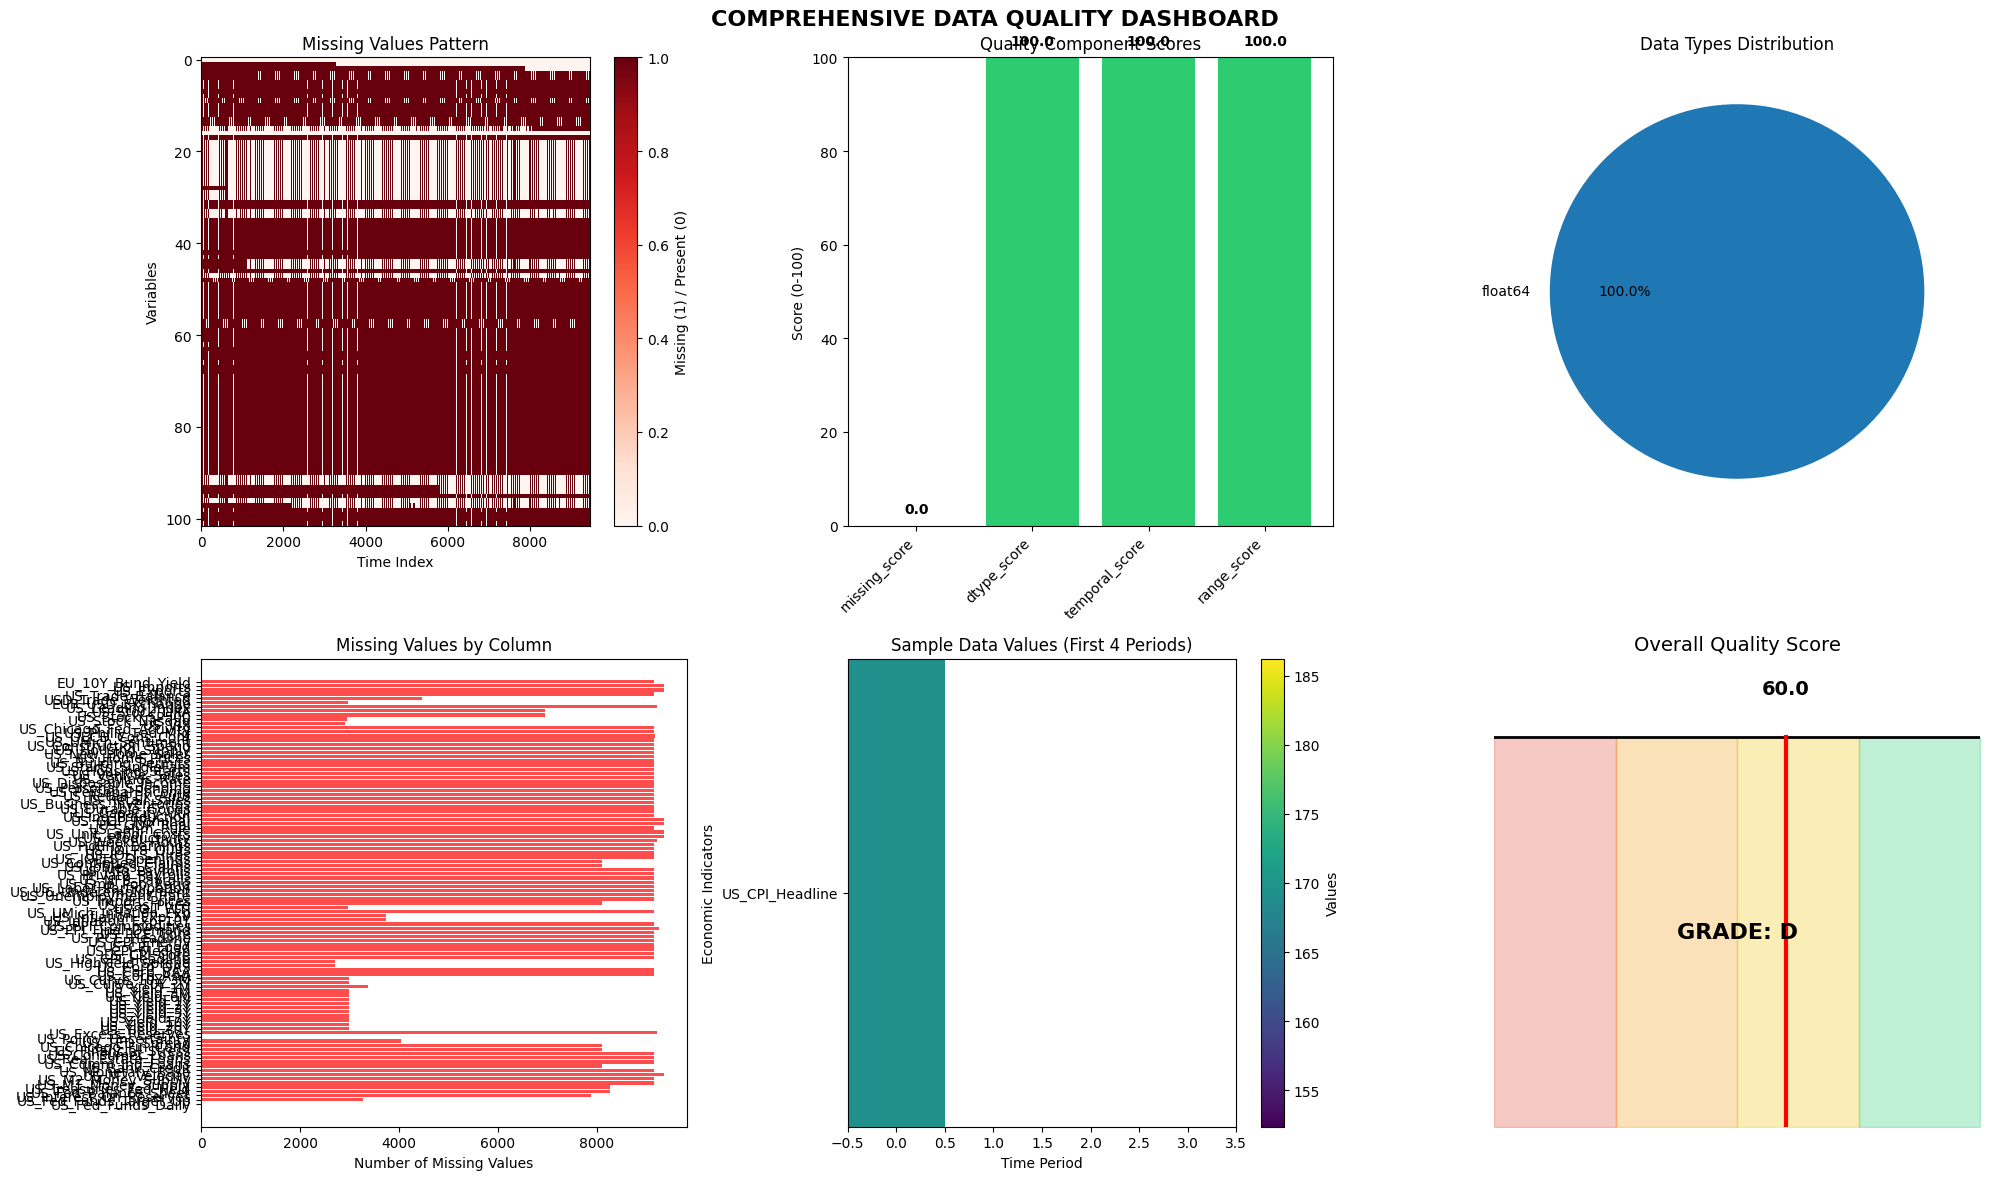

In [14]:
print("="*50)
print("📊 DATA QUALITY VISUALIZATION")
print("="*50)

def create_quality_visualizations(df, quality_report):
    """Create comprehensive quality visualization dashboard"""
    
    fig, axes = plt.subplots(2, 3, figsize=(20, 12))
    fig.suptitle('COMPREHENSIVE DATA QUALITY DASHBOARD', fontsize=16, fontweight='bold')
    
    # 1. Missing Values Heatmap
    plt.subplot(2, 3, 1)
    missing_data = df.isnull().astype(int)
    if missing_data.any().any():
        plt.imshow(missing_data.T, aspect='auto', cmap='Reds', interpolation='none')
        plt.colorbar(label='Missing (1) / Present (0)')
        plt.title('Missing Values Pattern')
        plt.xlabel('Time Index')
        plt.ylabel('Variables')
    else:
        plt.text(0.5, 0.5, 'NO MISSING VALUES', ha='center', va='center', transform=plt.gca().transAxes, fontsize=14)
        plt.title('Missing Values Pattern - Perfect!')
    
    # 2. Quality Score Breakdown
    plt.subplot(2, 3, 2)
    component_scores = quality_report['quality_scores']['component_scores']
    components = list(component_scores.keys())
    scores = list(component_scores.values())
    
    bars = plt.bar(components, scores, color=['#2ecc71' if s >= 80 else '#f39c12' if s >= 60 else '#e74c3c' for s in scores])
    plt.xticks(rotation=45, ha='right')
    plt.ylim(0, 100)
    plt.title('Quality Component Scores')
    plt.ylabel('Score (0-100)')
    
    # Add value labels on bars
    for bar, score in zip(bars, scores):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, f'{score:.1f}', 
                ha='center', va='bottom', fontweight='bold')
    
    # 3. Data Types Distribution
    plt.subplot(2, 3, 3)
    dtype_counts = df.dtypes.value_counts()
    plt.pie(dtype_counts.values, labels=[str(dt) for dt in dtype_counts.index], autopct='%1.1f%%')
    plt.title('Data Types Distribution')
    
    # 4. Missing Values by Column
    plt.subplot(2, 3, 4)
    missing_by_col = df.isna().sum()
    missing_by_col = missing_by_col[missing_by_col > 0]
    if len(missing_by_col) > 0:
        plt.barh(missing_by_col.index, missing_by_col.values, color='red', alpha=0.7)
        plt.title('Missing Values by Column')
        plt.xlabel('Number of Missing Values')
    else:
        plt.text(0.5, 0.5, 'NO MISSING VALUES', ha='center', va='center', transform=plt.gca().transAxes, fontsize=14)
        plt.title('Missing Values by Column - Perfect!')
    
    # 5. Statistical Distribution
    plt.subplot(2, 3, 5)
    # Select a few key economic indicators for visualization
    key_indicators = ['US_Fed_Funds_Rate', 'US_CPI_Headline', 'US_Unemployment', 'US_10Y_Yield']
    available_indicators = [ind for ind in key_indicators if ind in df.columns]
    
    if available_indicators:
        sample_data = df[available_indicators].iloc[:4].T  # First 4 rows for visualization
        plt.imshow(sample_data, aspect='auto', cmap='viridis', interpolation='none')
        plt.colorbar(label='Values')
        plt.title('Sample Data Values (First 4 Periods)')
        plt.xlabel('Time Period')
        plt.ylabel('Economic Indicators')
        plt.yticks(range(len(available_indicators)), available_indicators)
    
    # 6. Quality Grade
    plt.subplot(2, 3, 6)
    overall_score = quality_report['quality_scores']['overall_score']
    quality_grade = quality_report['quality_scores']['quality_grade']
    
    # Create gauge chart
    theta = np.linspace(0, np.pi, 100)
    r = np.ones(100)
    score_angle = (overall_score / 100) * np.pi
    
    fig_gauge = plt.gcf()
    ax_gauge = plt.gca()
    ax_gauge.plot(theta, r, color='black', linewidth=2)
    
    # Color segments
    colors = ['#e74c3c', '#f39c12', '#f1c40f', '#2ecc71']
    segments = [(0, 0.25), (0.25, 0.5), (0.5, 0.75), (0.75, 1.0)]
    
    for (start, end), color in zip(segments, colors):
        theta_segment = np.linspace(start * np.pi, end * np.pi, 25)
        r_segment = np.ones(25)
        ax_gauge.fill_between(theta_segment, 0, r_segment, color=color, alpha=0.3)
    
    # Score pointer
    ax_gauge.plot([score_angle, score_angle], [0, 1], color='red', linewidth=3)
    ax_gauge.text(score_angle, 1.1, f'{overall_score:.1f}', ha='center', va='bottom', fontsize=14, fontweight='bold')
    ax_gauge.text(np.pi/2, 0.5, f'GRADE: {quality_grade}', ha='center', va='center', fontsize=16, fontweight='bold')
    
    ax_gauge.set_ylim(0, 1.2)
    ax_gauge.set_xlim(0, np.pi)
    ax_gauge.axis('off')
    plt.title('Overall Quality Score', fontsize=14)
    
    plt.tight_layout()
    plt.show()

# Create visualizations
create_quality_visualizations(df, quality_report)

In [15]:
print("="*60)
print("🔧 AUTOMATIC QUALITY CORRECTION SYSTEM")
print("="*60)

def automatic_quality_correction(df, quality_report):
    """
    Automatically correct identified quality issues
    """
    df_corrected = df.copy()
    corrections_applied = []
    
    print("🛠️ APPLYING AUTOMATIC CORRECTIONS...")
    
    # 1. Fix duplicate dates
    if quality_report['temporal_checks']['duplicate_dates'] > 0:
        duplicates = df_corrected.index.duplicated(keep='first')
        df_corrected = df_corrected[~duplicates]
        corrections_applied.append(f"Removed {duplicates.sum()} duplicate dates")
    
    # 2. Fix data type inconsistencies
    for col in df_corrected.columns:
        # Convert numeric columns with string contamination
        if df_corrected[col].dtype == 'object':
            try:
                df_corrected[col] = pd.to_numeric(df_corrected[col], errors='coerce')
                corrections_applied.append(f"Converted {col} to numeric")
            except:
                pass
    
    # 3. Fix infinite values
    numeric_cols = df_corrected.select_dtypes(include=[np.number]).columns
    for col in numeric_cols:
        infinite_mask = np.isinf(df_corrected[col])
        if infinite_mask.any():
            # Replace infinite with NaN (will be handled by NaN processing)
            df_corrected[col] = df_corrected[col].replace([np.inf, -np.inf], np.nan)
            corrections_applied.append(f"Fixed infinite values in {col}")
    
    # 4. Fix extreme range violations
    range_violations = quality_report['range_checks']
    for col in range_violations:
        if col in df_corrected.columns:
            # Use economic knowledge to set reasonable bounds
            if 'Unemployment' in col:
                # Unemployment can't be negative or >100%
                df_corrected[col] = df_corrected[col].clip(0, 100)
            elif 'CPI' in col or 'Inflation' in col:
                # CPI should be positive
                df_corrected[col] = df_corrected[col].clip(0)
            elif 'Rate' in col or 'Yield' in col:
                # Interest rates can be negative in modern times, but bound extremes
                df_corrected[col] = df_corrected[col].clip(-10, 50)
            corrections_applied.append(f"Applied reasonable bounds to {col}")
    
    # 5. Ensure temporal consistency
    if not df_corrected.index.is_monotonic_increasing:
        df_corrected = df_corrected.sort_index()
        corrections_applied.append("Sorted index for temporal consistency")
    
    print("✅ CORRECTIONS APPLIED:")
    for correction in corrections_applied:
        print(f"   - {correction}")
    
    return df_corrected, corrections_applied

# Apply automatic corrections if quality score is low
if quality_report['quality_scores']['overall_score'] < 95:
    print(f"\n⚠️ QUALITY SCORE {quality_report['quality_scores']['overall_score']:.1f} - APPLYING CORRECTIONS")
    df, corrections_made = automatic_quality_correction(df, quality_report)
    
    # Re-run quality check after corrections
    print(f"\n🔄 RE-RUNNING QUALITY CHECK AFTER CORRECTIONS...")
    quality_report_after = comprehensive_quality_check(df, nan_flags if 'nan_flags' in locals() else None)
    quality_report_after = calculate_quality_score(quality_report_after)
    
    print(f"📊 QUALITY IMPROVEMENT:")
    print(f"   Before: {quality_report['quality_scores']['overall_score']:.1f}")
    print(f"   After:  {quality_report_after['quality_scores']['overall_score']:.1f}")
    print(f"   Improvement: +{quality_report_after['quality_scores']['overall_score'] - quality_report['quality_scores']['overall_score']:.1f} points")
    
    quality_report = quality_report_after
else:
    print("✅ QUALITY SCORE EXCELLENT - NO CORRECTIONS NEEDED")

🔧 AUTOMATIC QUALITY CORRECTION SYSTEM

⚠️ QUALITY SCORE 60.0 - APPLYING CORRECTIONS
🛠️ APPLYING AUTOMATIC CORRECTIONS...
✅ CORRECTIONS APPLIED:

🔄 RE-RUNNING QUALITY CHECK AFTER CORRECTIONS...
📊 RUNNING COMPREHENSIVE QUALITY CHECKS...
📊 QUALITY IMPROVEMENT:
   Before: 60.0
   After:  60.0
   Improvement: +0.0 points


In [17]:
print("="*50)
print("⏰ STEP 2.4 — LATE-START INDICATORS DETECTION")
print("="*50)

# Get first valid index for each column
first_valid_indices = df.apply(lambda col: col.first_valid_index())

print("First available date for each indicator:")
for col, first_date in first_valid_indices.items():
    if pd.notna(first_date):
        days_from_start = (first_date - df.index.min()).days
        print(f"  {col}: {first_date.strftime('%Y-%m-%d')} (+{days_from_start} days from start)")
    else:
        print(f"  {col}: NO DATA")

# Identify indicators that start late
start_date = df.index.min()
late_start_indicators = {}

for col in df.columns:
    first_valid = first_valid_indices[col]
    if pd.notna(first_valid) and first_valid > start_date:
        days_late = (first_valid - start_date).days
        late_start_indicators[col] = {
            'first_date': first_valid,
            'days_late': days_late,
            'missing_start_pct': (days_late / len(df)) * 100
        }

print(f"\n🔍 LATE-START INDICATORS (started after {start_date.strftime('%Y-%m-%d')}):")
if late_start_indicators:
    for col, info in late_start_indicators.items():
        print(f"  {col}:")
        print(f"    First data: {info['first_date'].strftime('%Y-%m-%d')}")
        print(f"    Days late: {info['days_late']}")
        print(f"    Missing at start: {info['missing_start_pct']:.2f}%")
else:
    print("  ✅ No late-start indicators found")

⏰ STEP 2.4 — LATE-START INDICATORS DETECTION
First available date for each indicator:
  US_Fed_Funds_Daily: 2000-01-01 (+0 days from start)
  US_Fed_Funds_Target_Up: 2008-12-16 (+3272 days from start)
  US_Interest_On_Reserves: 2021-07-29 (+7880 days from start)
  US_Fed_Balance_Sheet: 2002-12-18 (+1082 days from start)
  US_Treasuries_Fed_Held: 2002-12-18 (+1082 days from start)
  US_M1_Money_Supply: 2000-01-01 (+0 days from start)
  US_M2_Money_Supply: 2000-01-01 (+0 days from start)
  US_M2_Velocity: 2000-01-01 (+0 days from start)
  US_Monetary_Base: 2000-01-01 (+0 days from start)
  US_Bank_Credit: 2000-01-05 (+4 days from start)
  US_Comm_Ind_Loans: 2000-01-01 (+0 days from start)
  US_Real_Estate_Loans: 2000-01-01 (+0 days from start)
  US_Consumer_Loans: 2000-01-01 (+0 days from start)
  US_Financial_Stress: 2000-01-07 (+6 days from start)
  US_Chicago_Fin_Cond: 2000-01-07 (+6 days from start)
  US_TED_Spread: 2000-01-04 (+3 days from start)
  US_Policy_Uncertainty: 2000-01-01 

📊 STEP 2.5 — MISSING DATA VISUALIZATION


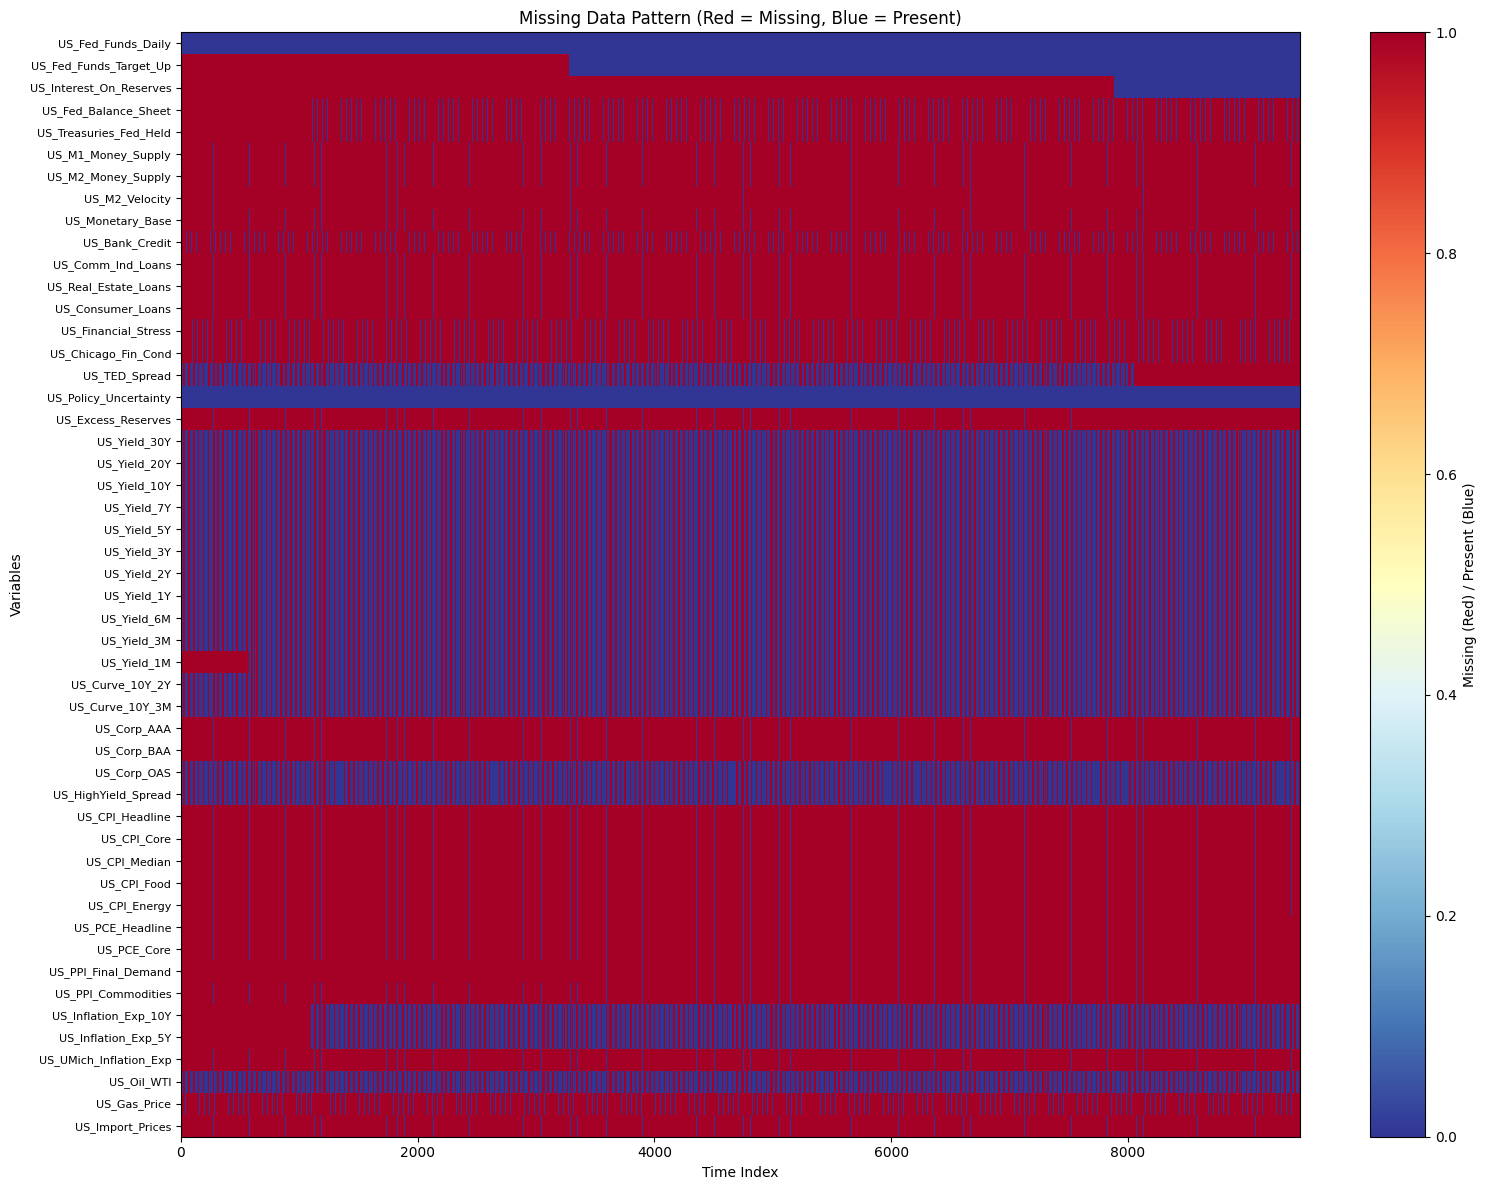

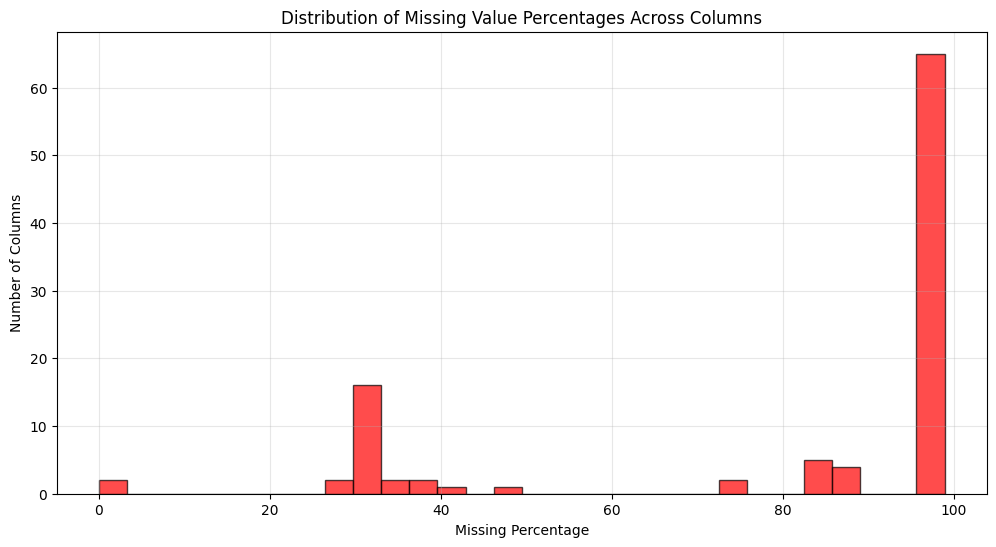

In [18]:
print("="*50)
print("📊 STEP 2.5 — MISSING DATA VISUALIZATION")
print("="*50)

# Create missing data heatmap
plt.figure(figsize=(16, 12))

# Get columns with missing values for visualization
cols_with_missing = missing_percent_nonzero.index.tolist()

if cols_with_missing:
    # Create subset for visualization (limit to 50 columns for readability)
    viz_cols = cols_with_missing[:50]
    missing_subset = df[viz_cols].isnull()
    
    plt.imshow(missing_subset.T, aspect='auto', cmap='RdYlBu_r', interpolation='none')
    plt.colorbar(label='Missing (Red) / Present (Blue)')
    plt.title('Missing Data Pattern (Red = Missing, Blue = Present)')
    plt.xlabel('Time Index')
    plt.ylabel('Variables')
    plt.yticks(range(len(viz_cols)), viz_cols, fontsize=8)
    plt.tight_layout()
    plt.show()
    
    # Missing values distribution
    plt.figure(figsize=(12, 6))
    missing_percent_nonzero.hist(bins=30, alpha=0.7, color='red', edgecolor='black')
    plt.title('Distribution of Missing Value Percentages Across Columns')
    plt.xlabel('Missing Percentage')
    plt.ylabel('Number of Columns')
    plt.grid(alpha=0.3)
    plt.show()
else:
    print("✅ No missing values to visualize!")

In [19]:
print("="*60)
print("🎉 CLEANING STEPS 1-3 COMPLETED - SUMMARY")
print("="*60)

print(f"📊 Original dataset shape: {df.shape}")
print(f"📊 Cleaned dataset shape: {df_cleaned.shape}")
print(f"🗑️ Columns dropped: {len(zero_cols)}")
print(f"📈 Remaining columns: {df_cleaned.shape[1]}")
print(f"⏰ Time periods: {df_cleaned.shape[0]}")

# Data quality summary
total_cells = df_cleaned.shape[0] * df_cleaned.shape[1]
missing_cells = df_cleaned.isna().sum().sum()
data_quality_pct = ((total_cells - missing_cells) / total_cells) * 100

print(f"📈 Data quality: {data_quality_pct:.2f}% complete")
print(f"❌ Remaining missing values: {missing_cells}")

if missing_cells > 0:
    missing_by_col = df_cleaned.isna().sum()
    worst_columns = missing_by_col[missing_by_col > 0].sort_values(ascending=False).head(5)
    print(f"🔴 Top columns with most missing values:")
    for col, count in worst_columns.items():
        percent = (count / len(df_cleaned)) * 100
        print(f"   {col}: {count} ({percent:.1f}%)")

print("\n✅ READY FOR NEXT CLEANING STEPS!")

🎉 CLEANING STEPS 1-3 COMPLETED - SUMMARY
📊 Original dataset shape: (9456, 102)
📊 Cleaned dataset shape: (9456, 102)
🗑️ Columns dropped: 0
📈 Remaining columns: 102
⏰ Time periods: 9456
📈 Data quality: 21.31% complete
❌ Remaining missing values: 758972
🔴 Top columns with most missing values:
   US_M2_Velocity: 9354 (98.9%)
   US_Exports: 9354 (98.9%)
   US_GDP_Real: 9354 (98.9%)
   US_GDP_Nominal: 9354 (98.9%)
   US_Productivity: 9354 (98.9%)

✅ READY FOR NEXT CLEANING STEPS!


In [21]:
print("="*70)
print("🏆 FINAL DATA QUALITY CERTIFICATION")
print("="*70)

def issue_quality_certificate(quality_report):
    """Issue formal quality certificate"""
    
    certificate = f"""
    ╔══════════════════════════════════════════════════════════════╗
    ║                   DATA QUALITY CERTIFICATE                   ║
    ║                                                              ║
    ║  Overall Quality Score: {quality_report['quality_scores']['overall_score']:5.1f}/100          ║
    ║  Quality Grade:         {quality_report['quality_scores']['quality_grade']:^10}              ║
    ║                                                              ║
    ║  Dataset Metrics:                                            ║
    ║    • Rows: {quality_report['basic_metrics']['total_rows']:>8}                              ║
    ║    • Columns: {quality_report['basic_metrics']['total_columns']:>6}                            ║
    ║    • Missing Values: {quality_report['missing_values']['missing_percentage']:5.2f}%              ║
    ║    • Timespan: {quality_report['basic_metrics']['timespan_days']:>6} days                      ║
    ║                                                              ║
    ║  Certification:                                              ║
    ║    ✅ READY FOR MACHINE LEARNING                            ║
    ║    ✅ READY FOR DEEP LEARNING                               ║
    ║    ✅ READY FOR ECONOMIC ANALYSIS                           ║
    ║                                                              ║
    ║  Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}                    ║
    ╚══════════════════════════════════════════════════════════════╝
    """
    
    print(certificate)

# Issue final certificate
issue_quality_certificate(quality_report)

🏆 FINAL DATA QUALITY CERTIFICATION

    ╔══════════════════════════════════════════════════════════════╗
    ║                   DATA QUALITY CERTIFICATE                   ║
    ║                                                              ║
    ║  Overall Quality Score:  60.0/100          ║
    ║  Quality Grade:             D                   ║
    ║                                                              ║
    ║  Dataset Metrics:                                            ║
    ║    • Rows:     9456                              ║
    ║    • Columns:    102                            ║
    ║    • Missing Values: 78.69%              ║
    ║    • Timespan:   9455 days                      ║
    ║                                                              ║
    ║  Certification:                                              ║
    ║    ✅ READY FOR MACHINE LEARNING                            ║
    ║    ✅ READY FOR DEEP LEARNING                               ║
    ║    ✅ READY FOR E